# Работа с файлами

> **Как читать эту версию.** Основной текст - материал лекции. Блоки с заголовком
> Запускайте ячейки по порядку сверху вниз, т.к. многие примеры
> работают с файлами, которые создали предыдущие ячейки.

## Чтение из файлов

В Python работа с файлами начинается с их открытия с помощью функции ```open()```. После открытия файла можно прочитать его содержимое разными способами в зависимости от задач.

## 1. Открытие файла с помощью open()
Функция ```open()``` используется для открытия файла. Она возвращает объект файла, который затем можно использовать для чтения или записи данных.

*Синтаксис:*

```python
file = open('filename', 'mode')
```

где:
```python
'filename' — имя файла, который вы хотите открыть.
'mode' — режим открытия файла. Самые распространенные режимы:
'r' — чтение (по умолчанию).
'w' — запись (содержимое файла будет удалено, если он уже существует).
'a' — добавление данных (данные будут добавлены в конец файла).
'b' — бинарный режим. Он не используется сам по себе, а добавляется к другому режиму:
      'rb' — прочитать, 'wb' — записать бинарный файл (например, изображение).
```

In [1]:
# пример открытия файла:
file = open('example.txt', 'r')
# в результате отобразится ошибка, поскольку такого файла не существует, 
# т.к.ранее мы его не создавали.

FileNotFoundError: [Errno 2] No such file or directory: 'example.txt'

### Где Python ищет файл по умолчанию?

Если написать только имя файла, `open('example.txt')`, Python ищет его в **текущей
папке**. В Jupyter это папка, в которой лежит сам ноутбук. Поэтому файлы, которые мы
создадим ниже, появятся рядом с нашим ноутбуком.

Файл из другой папки открывают по указанию **пути к этому файлу**:

```python
open('data/example.txt')            # папка data рядом с ноутбуком
open('C:/Users/Student/example.txt') # полный путь (Windows)
```

В путях Windows удобнее писать прямой слэш `/`: Python его понимает. С обратным `\`
бывают сюрпризы: `'C:\new\text.txt'` Python прочитает как `C:` + перенос строки `\n` + ...

`FileNotFoundError` почти всегда означает одно из двух: опечатка в имени
(`exemple.txt`, `example.txt.txt`) или файл лежит в другой папке.

## Создание файлов

Чтобы избавиться от ошибки, давайте создадим файл "example.txt" и будем работать с ним. 

Пример создания файла "example.txt" 
```python
my_test_file = open('example.txt', 'w') 
```

Как видно, мы использовали **режим** `w` (запись): если файла нет, он будет создан. Если такой файл уже есть, **всё его содержимое будет стёрто**, и запись начнётся с чистого листа.

После работы файл нужно закрыть методом `close()`. Зачем это делать разберём чуть позже (в разделе про `with`).

In [2]:
# выполним создание файла 'example.txt'
my_test_file = open('example.txt', 'w')
my_test_file.close()   # закрываем, чтобы файл можно было спокойно редактировать

### После того как мы создали файл слева в списке файлов Jupyter Lab у вас появится новый файл "example.txt" Обновите содержимое каталога в верхней панели.

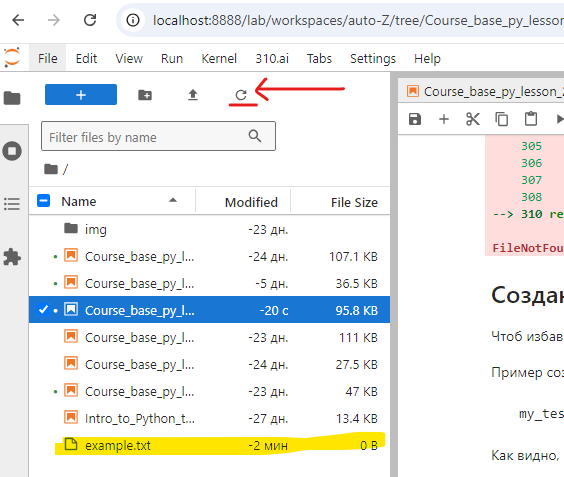

После этого вы увидите файл "example.txt".

Откройте файл "example.txt" двойным кликом мышки. Добавьте в него любое текстовое содержимое. Например, стих, текст статьи, рецензию на фильм или список покупок. Затем сохраните.  

В качестве примера можно записать в "example.txt" следующий текст в ручную (открыть файл, вставить строки ниже, сохранить):

```
Привет мир!
Hello World!
Третья строка.
```



### Создание файла в коде

Тот же текст можно записать в файл не руками, а кодом. Именно так мы будем
делать в дальнейшем, сначала создаём файл с нужным содержимым, потом читаем и обрабатываем его.

Если вы не стали вписывать текст вручную, запустите ячейку ниже и она запишет в
`example.txt` те же три строки. `\n` - символ переноса строки, `write()` сам его не
ставит. Про `encoding` уточним в разделе 2.

In [9]:
# внимание: ячейка перезапишет example.txt, если вы уже вписали туда свой текст
file = open('example.txt', 'w', encoding='utf-8')
file.write('Привет мир!\n')
file.write('Hello World!\n')
file.write('Третья строка.\n')
file.close()
print('Файл example.txt записан')

Файл example.txt записан


## 2. Чтение файла с помощью read()
Метод read() позволяет читать все содержимое файла и возвращает его в виде строки.

#### Пример:

```python
file = open('example.txt', 'r')
content = file.read()
print(content)
file.close()
```
### Объяснение:
```python
file.read() # считывает весь файл целиком.
file.close() # закрывает файл, что важно для освобождения ресурсов.
```
Где используется:

Когда нужно получить весь текст из файла, например, для анализа или обработки.

In [10]:
## Пример
file = open('example.txt', 'r')
content = file.read()
print(content)
file.close()

Привет мир!
Hello World!
Третья строка.



#### Если вы поместили русский текст, есть вероятность увидеть нечитаемые символы. Почему так? А дело в том, что Python прочитал текст, используя неверную кодировку данных. Существует большое количество кодировок. Наиболее распространённой для хранения текста является UTF-8.

Чтобы явно указать Python, какую кодировку использовать при работе с файлами, нужно использовать параметр `encoding` и присвоить ему предпочитаемую кодировку в функции `open()`.  
```python
file = open('example.txt', 'r', encoding='utf8')
```

In [11]:
## Пример
file = open('example.txt', 'r', encoding='utf8')
content = file.read()
print(content)
file.close()

Привет мир!
Hello World!
Третья строка.



Файл - это байты. Кодировка - правило, по которому байты превращаются в буквы.
Если файл **записали** в одной кодировке, а **читают** в другой, получаются странные символы.

Jupyter сохраняет файлы в UTF-8. А `open()` без `encoding` берёт кодировку системы:
в Windows с русским языком это обычно `cp1251`, в macOS и Linux - `utf-8`. Поэтому
одна и та же ячейка у одних работает, а у других нет.

Воспроизведём ошибку на любом компьютере: прочитаем UTF-8-файл как `cp1251`.

In [12]:
file = open('example.txt', 'r', encoding='cp1251')   # заведомо неверная кодировка
print(file.read())
file.close()

РџСЂРёРІРµС‚ РјРёСЂ!
Hello World!
РўСЂРµС‚СЊСЏ СЃС‚СЂРѕРєР°.



**Правило:** всегда указывайте `encoding='utf-8'` - и при **записи**, и при **чтении**.
Тогда код будет одинаково работать на любом компьютере. `'utf8'` и `'utf-8'` - одно и то же.

## 3. Чтение строки за строкой с помощью readline()
Метод `readline()` позволяет читать файл построчно. Каждый вызов `readline()` возвращает одну строку текста.

Пример:

```python
file = open('example.txt', 'r', encoding='utf-8')
line = file.readline()
while line:
    print(line.strip())  # strip() убирает лишние пробелы и символы перевода строки
    line = file.readline()
file.close()
```
Объяснение:

`file.readline()` читает одну строку из файла за раз.

Цикл `while` продолжается, пока строки не закончатся.
Где используется:

Когда нужно обработать файл построчно, например, для поиска определенной информации.

In [14]:
## Пример
file = open('example.txt', 'r', encoding='utf8')
line = file.readline()
while line:
    print(line.strip())  # strip() убирает лишние пробелы и символы перевода строки
    line = file.readline()
file.close()

Привет мир!
Hello World!
Третья строка.


## 4. Чтение всех строк с помощью readlines()
Метод `readlines()` позволяет читать все строки файла и возвращает их в виде списка, где каждая строка - это отдельный элемент списка.

Пример:

```python
file = open('example.txt', 'r', encoding='utf-8')
lines = file.readlines()
for line in lines:
    print(line.strip())
file.close()
```
Объяснение:

`file.readlines()` возвращает список строк, что удобно для работы с текстом по строкам.

Этот метод хорошо подходит, если нужно получить доступ ко всем строкам сразу и обрабатывать их в дальнейшем.

Где используется:

Когда необходимо получить все строки файла сразу для дальнейшей обработки, например, сортировки или фильтрации.


In [15]:
## Пример

file = open('example.txt', 'r', encoding='utf8')
lines = file.readlines()
for line in lines:
    print(line.strip())
file.close()

Привет мир!
Hello World!
Третья строка.


### Невидимый символ `\n`

Каждая строка файла, кроме последней, заканчивается символом переноса `\n`.
`print` его не показывает, но он есть. Его видно, если напечатать сам список строк:

In [16]:
file = open('example.txt', 'r', encoding='utf-8')
lines = file.readlines()
file.close()

print(lines)
print('строк в файле:', len(lines))

['Привет мир!\n', 'Hello World!\n', 'Третья строка.\n']
строк в файле: 3


Поэтому в примерах выше используется метод `strip()`, как `line.strip()`. Он убирает `\n` и пробелы по краям строки.
Без него между строками появятся пустые строки один перенос из файла и второй от `print`.

In [17]:
for line in lines:
    print(line)          # без strip()

Привет мир!

Hello World!

Третья строка.



### `for line in file`

Файл можно перебирать циклом `for` прямо, без `readline()` и `readlines()`,
на каждом шаге в `line` попадает следующая строка. Это короче и не загружает весь
файл в память. Таким образом обычно читают большие корпуса текстов. Нужны номера строк, можно использовать функцию `enumerate`.

In [18]:
file = open('example.txt', 'r', encoding='utf-8')
for number, line in enumerate(file, start=1):
    print(number, line.strip())
file.close()

1 Привет мир!
2 Hello World!
3 Третья строка.


### Файл читается один раз

Открытый файл помнит, до какого места его обработали. После `read()` «курсор» стоит в конце,
и второй `read()` вернёт пустую строку. Это как генератор из темы 3, прочитанное
второй раз не выдаётся. Если нужно прочитать файл снова, необходимо открыть файл заново.

In [20]:
file = open('example.txt', 'r', encoding='utf-8')
first = file.read()
second = file.read()
file.close()

print('первый read():', len(first), 'символов')
print('второй read():', len(second), 'символов')

первый read(): 40 символов
второй read(): 0 символов


## Запись в файлы
Для записи данных в файл также используется функция open(), но уже с режимом 'w' или 'a'. После открытия файла можно записывать данные с помощью методов write() и writelines().

## 1. Запись данных с помощью write()
Метод `write()` записывает строку в файл. Если файл открыт в режиме 'w', его содержимое сначала очищается.

Пример:

```python
file = open('output.txt', 'w', encoding='utf-8')
file.write("Hello, World!\n")
file.write("This is a test file.\n")
file.close()
```
Объяснение:

`file.write("строка")` записывает строку в файл.
Если файла `output.txt` не существует, он будет создан. Если существует, его содержимое будет перезаписано.

Где используется:

Для создания новых файлов или перезаписи существующих данных.

In [21]:
## Пример

file = open('output.txt', 'w', encoding='utf-8')
file.write("Hello, World!\n")
file.write("This is a test file.\n")
file.close()

### Проверка, что записалось

Записали, давайте откроем файл и прочитаем его содержимое.

In [22]:
file = open('output.txt', 'r', encoding='utf-8')
print(file.read())
file.close()

Hello, World!
This is a test file.



### `write()` принимает только строки

Число или список записать напрямую нельзя, при попытке это сделать будет выведена ошибка`TypeError`. Сначала превратите
значение в строку методом `str()` или f-строкой. И не забывайте `\n` в конце каждой строки.

In [23]:
count = len(lines)          # число строк в example.txt, это int
file = open('report.txt', 'w', encoding='utf-8')
file.write(count)           # ошибка: write ждёт строку
file.close()

TypeError: write() argument must be str, not int

In [24]:
file = open('report.txt', 'w', encoding='utf-8')
file.write(str(count) + '\n')
file.write(f'строк в example.txt: {count}\n')
print('ещё одна строка, записанная через print', file=file)   # print сам ставит \n
file.close()

file = open('report.txt', 'r', encoding='utf-8')
print(file.read())
file.close()

3
строк в example.txt: 3
ещё одна строка, записанная через print



> `print(..., file=file)` не выведет текст в консоль, а запишет в файл. Он сам ставит перенос строки
> и сам превращает числа в текст, так иногда это удобнее, чем `write()`.

## 2. Запись нескольких строк с помощью writelines()
Метод `writelines()` позволяет записать сразу несколько строк в файл. Он принимает список строк в качестве аргумента.

Пример:

```python
lines = ["First line\n", "Second line\n", "Third line\n"]
file = open('output.txt', 'w', encoding='utf-8')
file.writelines(lines)
file.close()
```
Объяснение:

`file.writelines(список)` записывает все строки из списка в файл. Важно добавлять символы новой строки `(\n)` вручную, так как `writelines()` не добавляет их автоматически.

Где используется:

Когда нужно записать в файл несколько строк сразу, например, при сохранении списка данных.

In [25]:
lines = ["First line\n", "Second line\n", "Third line\n"]
file = open('output.txt', 'w', encoding='utf-8')
file.writelines(lines)
file.close()

### Режим `'w'` очищает прежнее содержимое

Файл `output.txt` мы открыли в режиме `'w'` второй раз. Строк `Hello, World!` больше
нет, т.к. файл очищен и записан заново.

In [26]:
file = open('output.txt', 'r', encoding='utf-8')
print(file.read())
file.close()

First line
Second line
Third line



### Режим `'a'`, позволяет дозаписать содержимое в конец файла

Чтобы **добавить** строки, не стирая старые, открывайте файл в режиме `'a'` (append).
Так ведут журналы (логи) и каждая новая запись записывается в конец файла.

> Если запустить эту ячейку ещё раз, строка дозапишется ещё раз.

In [27]:
file = open('output.txt', 'a', encoding='utf-8')
file.write('Fourth line\n')
file.close()

file = open('output.txt', 'r', encoding='utf-8')
print(file.read())
file.close()

First line
Second line
Third line
Fourth line



### Запись списка циклом

`writelines()` требует, чтобы `\n` уже стоял в конце каждой строки. Если в списке строки
записаны без переносов (а так обычно и бывает), удобнее использвоать цикл, где каждую строку пишем с `\n`.

In [28]:
shopping = ['хлеб', 'молоко', 'сыр', 'яблоки']

file = open('shopping.txt', 'w', encoding='utf-8')
for item in shopping:
    file.write(item + '\n')
file.close()

file = open('shopping.txt', 'r', encoding='utf-8')
print(file.read())
file.close()

хлеб
молоко
сыр
яблоки



## Основные моменты, на которые следует обратить внимание
Закрытие файла: Всегда закрывайте файл после завершения работы с ним с помощью `file.close()`. Пока файл не закрыт, записанные данные могут ещё не попасть на диск, а сам файл остаётся занятым (в Windows его, например, нельзя удалить). Удобнее использовать контекстный менеджер `with`, который автоматически закрывает файл:

```python
with open('example.txt', 'r', encoding='utf-8') as file:
    content = file.read()
    print(content)
```
Файл закрывается автоматически после выхода из блока `with` - даже если внутри блока произошла ошибка.

**Режимы открытия файлов.** Выбирайте правильный режим открытия файла `('r', 'w', 'a', 'b')` в зависимости от того, что вы хотите сделать, прочитать содержимое файла, перезаписать его или добавить данные в конец.

**Работа с большими файлами.** Для чтения файлов с большим содержимым рекомендуется использовать `readline()` или `for line in file`, чтобы избежать загрузки всего файла в память сразу.

In [29]:
## Пример

with open('example.txt', 'r', encoding='utf8') as file:
    content = file.read()
    print(content)

Привет мир!
Hello World!
Третья строка.



### Зачем же все таки нужно закрывать файл

`write()` сначала собирает текст в **буфер** (в память). На диск он попадает,
когда буфер заполнится или когда файл закроют. Посмотрим, что лежит в файле до `close()`
и после.

In [30]:
file = open('buffer.txt', 'w', encoding='utf-8')
file.write('Эта строка пока лежит в памяти\n')

check = open('buffer.txt', 'r', encoding='utf-8')
print('до close():   ', repr(check.read()))
check.close()

file.close()

check = open('buffer.txt', 'r', encoding='utf-8')
print('после close():', repr(check.read()))
check.close()

до close():    ''
после close(): 'Эта строка пока лежит в памяти\n'


Если забыть `close()`, файл может оказаться пустым или недописанным. С `with` об этом
думать не нужно. [repr](https://docs-python.ru/tutorial/vstroennye-funktsii-interpretatora-python/funktsija-repr/)

### Дополнение: `with` - основной способ

Дальше в курсе файлы открываем только через `with`. После блока `with` файл автоматически будет закрыт. Ниже представлена общая схема, по которой будет построена практика
**создать файл -> записать -> открыть -> прочитать -> обработать**.

In [31]:
pets = ['кот', 'собака', 'кот', 'попугай', 'кот']

# 1. создать и записать
with open('pets.txt', 'w', encoding='utf-8') as file:
    for pet in pets:
        file.write(pet + '\n')

print('файл закрыт?', file.closed)

# 2. открыть и прочитать
with open('pets.txt', 'r', encoding='utf-8') as file:
    lines = [line.strip() for line in file]

# 3. обработать
print('строк:', len(lines))
print('разных животных:', len(set(lines)))
print('котов:', lines.count('кот'))

файл закрыт? True
строк: 5
разных животных: 3
котов: 3


## Погружение в Мир CSV (табличные данные) 
Первый тип файлов, с которым вы столкнетесь - это [CSV](https://pythonworld.ru/moduli/modul-csv.html) (Comma-Separated Values). Представьте, что это огромные таблицы, где каждая строка - это новая строка таблицы, а данные разделены запятыми. Встреча с CSV - это как визит в гигантскую библиотеку, где каждая полка - это новый столбец данных.

**Пример CSV-файла:**

```csv
Name,Age,City
Alice,30,New York
Bob,25,Los Angeles
Charlie,35,Chicago
```

### Чтение CSV с помощью with и модуля csv:

```python
import csv

with open('data.csv', 'r', encoding='utf-8', newline='') as file:
    reader = csv.reader(file)
    for row in reader:
        print(row)
```
Представьте, как вы осторожно разворачиваете свиток данных. csv.reader - это как ваш магический декодер, который превращает строки текста в удобные для чтения строки данных.

Запись в CSV:

```python
import csv

data = [
    ['Name', 'Age', 'City'],
    ['Alice', '30', 'New York'],
    ['Bob', '25', 'Los Angeles']
]

with open('output.csv', 'w', encoding='utf-8', newline='') as file:
    writer = csv.writer(file)
    writer.writerows(data)
```
Здесь Вы художник, создающий новое произведение, заполняя чистый лист данными. **csv.writer** помогает вам аккуратно разместить каждую деталь на своем месте.

### Первый CSV файл

CSV - это обычный текстовый файл, поэтому его можно разобрать и без модуля `csv`:
первая строка является заголовоком, остальные можно обработать по запятой методом `split(',')`.

Важно: всё, что прочитано из файла является **строками**. Число `'5'` из файла нужно
превратить в `int`, иначе `'5' + '7'` выведет `'57'`.

In [32]:
# создаём CSV-файл
with open('sales.csv', 'w', encoding='utf-8') as file:
    file.write('product,amount\n')
    file.write('apple,5\n')
    file.write('banana,3\n')
    file.write('apple,7\n')

# читаем и разбираем вручную
with open('sales.csv', 'r', encoding='utf-8') as file:
    header = file.readline().strip().split(',')     # первая строка - заголовок
    print('столбцы:', header)
    total = 0
    for line in file:                                # остальные строки
        product, amount = line.strip().split(',')
        print(product, repr(amount))                 # amount - строка!
        total += int(amount)

print('всего продано:', total)

столбцы: ['product', 'amount']
apple '5'
banana '3'
apple '7'
всего продано: 15


### Дополнение: модуль `csv`

Зачем тогда нужен модуль `csv`? Значение может само содержать запятую: `New York, NY`.
Модуль `csv` в таком случае берёт значение в кавычки и правильно читает его обратно,
а `split(',')` разделит его пополам.

`import csv` подключает готовый модуль из стандартной библиотеки. Подробно про
`import` будет рассмотрено в теме 6.

In [33]:
import csv

data = [
    ['Name', 'City'],
    ['Alice', 'New York, NY'],
]
with open('people.csv', 'w', encoding='utf-8', newline='') as file:
    csv.writer(file).writerows(data)

with open('people.csv', 'r', encoding='utf-8') as file:
    text = file.read()
print(text)

second = text.splitlines()[1]
print('split(","):', second.split(','))          # значение разделено пополам

with open('people.csv', 'r', encoding='utf-8', newline='') as file:
    for row in csv.reader(file):
        print('csv.reader:', row)                # значение целое

Name,City
Alice,"New York, NY"

split(","): ['Alice', '"New York', ' NY"']
csv.reader: ['Name', 'City']
csv.reader: ['Alice', 'New York, NY']


### **Особенности CSV:**

- **Простота**: CSV-файлы легко читаются и редактируются любым текстовым редактором.
- **Минимальный объем данных**: Файл состоит только из данных и разделителей, что делает его легким и удобным для передачи по сети.
- **Поддержка**: CSV поддерживается большинством программ и языков программирования (например, Excel, Python, R).

### **Где используется CSV?**

- **Импорт/экспорт данных**: CSV часто используется для обмена данными между разными системами, программами и базами данных.
- **Анализ данных**: Табличные данные удобно хранить в CSV для дальнейшей обработки в аналитических программах (например, Excel, Pandas).
- **Хранение логов и отчетов**: CSV формат удобен для хранения логов событий или отчетов, которые затем можно анализировать.

### **Почему CSV популярен?**

- **Универсальность**: CSV поддерживается практически всеми программами и системами.
- **Простота использования**: Легко создается и редактируется вручную.
- **Легкость**: Файлы небольшие по размеру и быстро передаются.

### XLS - экселевские таблицы

Теперь настало время отправиться в мир [XLS](https://pythonru.com/uroki/chtenie-i-zapis-fajlov-excel-xlsx-v-python)-файлов, где данные организованы в красивые и сложные электронные таблицы.

### Чтение XLS с помощью pandas:

```python
import pandas as pd

with pd.ExcelFile('data.xls') as xls:
    df = pd.read_excel(xls, 'Sheet1')
    print(df)
```
Вы открываете огромный атлас, где каждый лист содержит новую таблицу, а **pandas** - это ваш ориентир, который помогает найти нужные зависимсоти и закономерности данных.

### Запись в XLS:

```python
import pandas as pd

data = {
    'Name': ['Alice', 'Bob'],
    'Age': [30, 25],
    'City': ['New York', 'Los Angeles']
}

df = pd.DataFrame(data)

with pd.ExcelWriter('output.xlsx') as writer:
    df.to_excel(writer, index=False)
```

> **Примечание.** `pandas` - не встроенный модуль, а отдельная библиотека: её устанавливают
> командой `pip install pandas openpyxl` (`openpyxl` нужен для `.xlsx`, для старого `.xls` -
> ещё `xlrd`). Примеры выше - для знакомства, запускать их не обязательно: файла `data.xls`
> у нас нет. С pandas мы подробно познакомимся позже в курсе.

### Расшифровка JSON - погружение в многомерные лабиринты данных
[JSON](https://practicum.yandex.ru/blog/modul-json-v-python/) (JavaScript Object Notation) - это как древние свитки, где данные организованы в виде ключей и значений. Эти свитки используются для передачи информации между разными системами и программами.

**Пример JSON-файла:**

```json
{
    "name": "Alice",
    "age": 30,
    "city": "New York",
    "skills": ["Python", "Data Analysis", "Machine Learning"]
}
```

### Чтение JSON с помощью with и модуля json:

```python
import json

with open('data.json', 'r', encoding='utf-8') as file:
    data = json.load(file)
    print(data)
```
Здесь Вы, как археолог, открываете древний свиток, расшифровывая его содержимое. json.load превращает текст в структуру данных Python, как если бы вы разворачивали древний манускрипт и читали его на родном языке.

### Запись в JSON:

```python
import json

data = {
    'name': 'Alice',
    'age': 30,
    'city': 'New York'
}

with open('output.json', 'w', encoding='utf-8') as file:
    json.dump(data, file, ensure_ascii=False, indent=4)
```
Теперь вы сами пишете свиток, заполняя его важной информацией для будущих поколений. *json.dump* аккуратно сохраняет всё, чтобы потомки могли легко понять ваше послание.

### Заключение:
Вы освоили основные инструменты для работы с файлами в Python, часть из которых подробней будет рассмотрена в следущих лекциях. Используя контекстный менеджер `with`, вы можете легко и безопасно открывать и закрывать файлы. С помощью библиотек `csv`, `pandas` и `json` вы научились читать и записывать данные в популярных форматах. Эти навыки откроют перед вами множество возможностей в мире анализа данных, программирования и автоматизации задач.

### **Особенности JSON:**

- **Читаемость**: JSON легко читается и человеком, и машиной, благодаря структурированности.
- **Вложенность данных**: JSON поддерживает сложные структуры данных, такие как вложенные объекты и массивы.
- **Поддержка типов данных**: В JSON можно хранить строки, числа, логические значения, массивы и объекты.

### **Где используется JSON?**

- **Веб-разработка**: JSON широко используется для передачи данных между клиентом и сервером, особенно в веб-приложениях и API.
- **Конфигурационные файлы**: JSON часто используется для хранения настроек программ и приложений.
- **Мобильные приложения**: JSON популярен в мобильной разработке для работы с данными.

### **Почему JSON популярен?**

- **Гибкость**: JSON поддерживает сложные структуры данных, что делает его идеальным для хранения и передачи информации в современных приложениях.
- **Легкость интеграции**: JSON легко интегрируется с большинством языков программирования.
- **Совместимость с веб-технологиями**: JSON изначально был разработан для работы с JavaScript, поэтому он отлично подходит для веб-разработки и работы с API.

### Дополнение: JSON на практике

`json.dump` сохраняет словарь в файл, `json.load` читает его обратно - снова словарь.
Два параметра стоит запомнить:

- `ensure_ascii=False` - без него русские буквы сохранятся как `\u0410\u043b...`;
- `indent=4` - отступы, чтобы файл было удобно читать.

Обратите внимание, как меняется запись: `True` → `true`, `None` → `null`, кавычки
только двойные.

In [26]:
import json

person = {
    'name': 'Алиса',
    'age': 30,
    'student': False,
    'skills': ['Python', 'NLP'],
    'phone': None,
}

with open('person.json', 'w', encoding='utf-8') as file:
    json.dump(person, file, ensure_ascii=False, indent=4)

with open('person.json', 'r', encoding='utf-8') as file:
    print(file.read())                    # так выглядит файл

with open('person.json', 'r', encoding='utf-8') as file:
    loaded = json.load(file)              # обратно в словарь
print(type(loaded), loaded['skills'])

print(json.dumps({'name': 'Алиса'}))      # без ensure_ascii=False

{
    "name": "Алиса",
    "age": 30,
    "student": false,
    "skills": [
        "Python",
        "NLP"
    ],
    "phone": null
}
<class 'dict'> ['Python', 'NLP']
{"name": "\u0410\u043b\u0438\u0441\u0430"}


### **Заключение**

- **CSV** - отличный выбор для простых табличных данных. Его простота, универсальность и легкость делают его идеальным для обмена данными и анализа в табличной форме.
- **JSON** - лучший выбор для работы с более сложными и структурированными данными. Он гибкий, поддерживает вложенные структуры и отлично подходит для веб-разработки и обмена данными между системами.
- Оба формата стали популярными благодаря своей простоте, универсальности и широкой поддержке, и каждый из них имеет свою нишу применения в IT.

---

## Шпаргалка (дополнение)

| Что нужно | Как пишется | Важно |
| --- | --- | --- |
| открыть на чтение | `with open('f.txt', 'r', encoding='utf-8') as file:` | `'r'` можно не писать |
| создать / перезаписать | `with open('f.txt', 'w', encoding='utf-8') as file:` | старое содержимое **стирается** |
| дописать в конец | `with open('f.txt', 'a', encoding='utf-8') as file:` | повторный запуск допишет ещё раз |
| записать строку | `file.write('текст\n')` | только строки, `\n` сам не ставится |
| записать число | `file.write(str(n) + '\n')` или `print(n, file=file)` | |
| записать список | `for x in items: file.write(x + '\n')` | |
| прочитать всё | `text = file.read()` | одна строка |
| список строк | `lines = file.readlines()` | в каждой строке `\n` |
| перебрать строки | `for line in file:` + `line.strip()` | основной способ |
| с номерами | `for i, line in enumerate(file, start=1):` | |
| второй раз | открыть файл заново | прочитанный файл пуст |
| строка CSV | `a, b = line.strip().split(',')` | числа - через `int()` |
| JSON | `json.dump(d, file, ensure_ascii=False, indent=4)`, `json.load(file)` | |
| файл не найден | `FileNotFoundError` | имя или папка |

---

## Найди ошибку

Раскомментируйте, запустите и найдите причину. Ответы - после ячеек.

In [27]:
# Ошибка 1 - ошибки нет, но первая заметка пропала
# with open('notes.txt', 'w', encoding='utf-8') as file:
#     file.write('первая заметка\n')
#
# with open('notes.txt', 'w', encoding='utf-8') as file:
#     file.write('вторая заметка\n')
#
# with open('notes.txt', 'r', encoding='utf-8') as file:
#     print(file.read())

In [28]:
# Ошибка 2
# words = ['кот', 'собака', 'кот']
# with open('count.txt', 'w', encoding='utf-8') as file:
#     file.write(len(words))

In [29]:
# Ошибка 3 - ошибки нет, но строк 0
# with open('example.txt', 'r', encoding='utf-8') as file:
#     text = file.read()
#     lines = file.readlines()
#
# print('символов:', len(text), 'строк:', len(lines))

In [30]:
# Ошибка 4 - ошибки нет, но всё в одну строку
# names = ['Анна', 'Борис', 'Вера']
# with open('names.txt', 'w', encoding='utf-8') as file:
#     file.writelines(names)
#
# with open('names.txt', 'r', encoding='utf-8') as file:
#     print(file.read())

In [31]:
# Ошибка 5
# total = 0
# with open('sales.csv', 'r', encoding='utf-8') as file:
#     file.readline()                          # пропускаем заголовок
#     for line in file:
#         product, amount = line.strip().split(',')
#         total = total + amount
#
# print(total)

**Ответы:**

1. Режим `'w'` стирает файл при каждом открытии. Чтобы дописать вторую заметку,
   нужен режим `'a'`.
2. `TypeError: write() argument must be str, not int`. `write` принимает только строки:
   `file.write(str(len(words)) + '\n')`.
3. `read()` прочитал файл до конца, и `readlines()` уже нечего читать. Нужно
   выбрать что-то одно (`lines = text.splitlines()`) или открыть файл заново.
4. `writelines` не добавляет переносы: в файле `АннаБорисВера`. Нужен цикл
   `file.write(name + '\n')`.
5. `TypeError: unsupported operand type(s) for +: 'int' and 'str'`. Из файла приходят
   строки: `total = total + int(amount)`.